# 04 Uplift: who is persuaded? (finding 6)

Models were trained on 80% of users and graded on the other 2.8 million (`uplift_analysis.py`, about 12 minutes). This notebook grades their saved scores. Write-up: `docs/uplift.md`.

In [1]:
from pathlib import Path
import json

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from incrementality.style import PAL, SOURCE, SOURCE_IOWA, apply, finish

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CRITEO = (ROOT / "data" / "processed" / "criteo_uplift.parquet").as_posix()
results = lambda name: json.loads((ROOT / "results" / f"{name}.json").read_text(encoding="utf-8"))
show = lambda name: display(Image(filename=str(ROOT / "figures" / name), width=900))
pd.set_option("display.float_format", "{:,.4f}".format)
apply()

In [2]:
from incrementality.uplift import capture, capture_diff, spend_capture

s = pd.read_parquet(ROOT / "data" / "processed" / "uplift_test_scores.parquet")
cost = ((s["treatment"] == 1) & (s["exposure"] == 1)).astype(float).to_numpy()
print(f"{len(s):,} held-out users")

2,795,953 held-out users


**Grading.** Rank users by a model's score and ask what share of the ads' total effect the top 10%, 20%... hold. The effect per user comes from doubly robust pseudo-outcomes (`psi`), which correct for the leak found in notebook 02.

In [3]:
rows = []
for outcome in ["visit", "conversion"]:
    psi = s[f"{outcome}_psi"].to_numpy()
    for model in ["x_learner", "t_learner", "response"]:
        score = s[f"{outcome}_{model}"].to_numpy()
        rows.append({"outcome": outcome, "model": model,
                     **{f"top {k:.0%} of users": capture(score, psi, k).lift_share for k in (0.1, 0.2, 0.3)},
                     "half the spend": spend_capture(score, psi, cost, 0.5).lift_share})
pd.DataFrame(rows).set_index(["outcome", "model"]).style.format("{:.0%}")

In [4]:
for outcome in ["visit", "conversion"]:
    psi = s[f"{outcome}_psi"].to_numpy()
    for k in (0.1, 0.2):
        d, lo, hi = capture_diff(s[f"{outcome}_x_learner"].to_numpy(), s[f"{outcome}_response"].to_numpy(), psi, k)
        print(f"{outcome:10s} top {k:.0%}: X-learner minus likely buyers {d:+.1%} (95% interval {lo:+.1%} to {hi:+.1%})")

visit      top 10%: X-learner minus likely buyers +11.7% (95% interval +7.1% to +16.2%)


visit      top 20%: X-learner minus likely buyers +1.2% (95% interval -1.9% to +4.4%)


conversion top 10%: X-learner minus likely buyers -1.3% (95% interval -9.2% to +6.5%)


conversion top 20%: X-learner minus likely buyers -0.1% (95% interval -7.8% to +7.6%)


The effect is concentrated (about 91% in the top fifth), but the simple likely-buyer ranking finds those users as well as the uplift models do, except for visits on a tight budget.

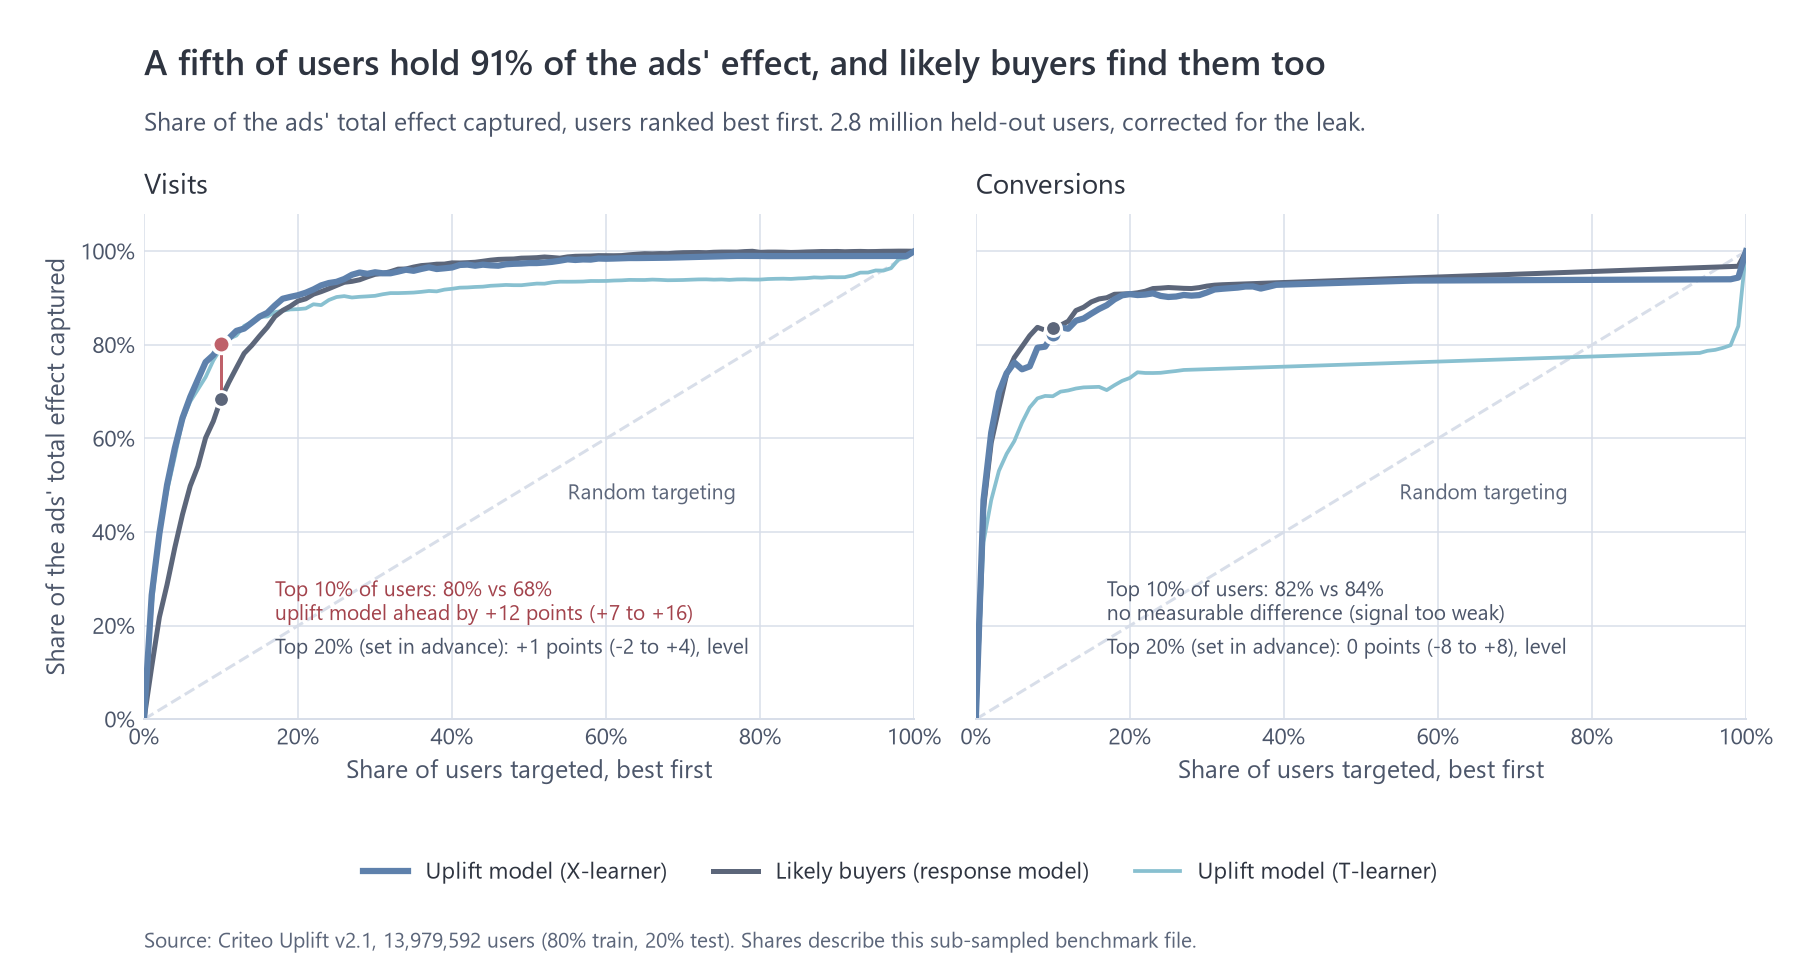

In [5]:
show("uplift/uplift_curves.png")

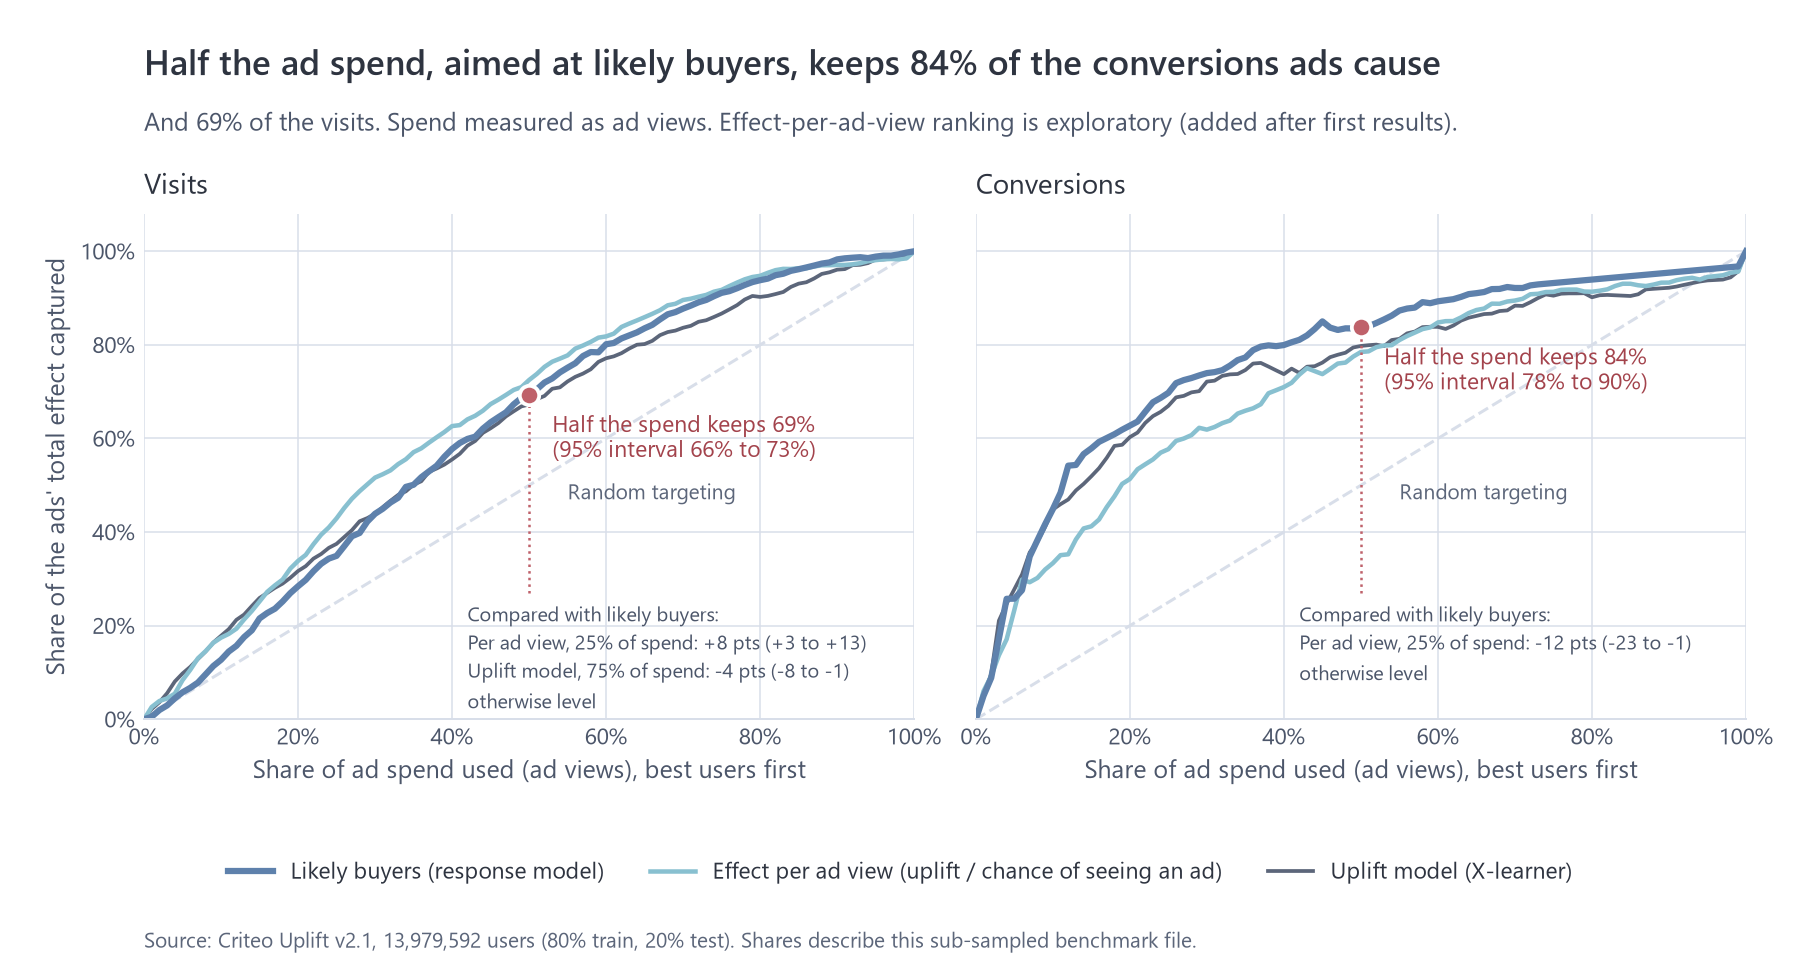

In [6]:
show("uplift/spend_curves.png")